In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.spatial import cKDTree


def find_repo_root(start: Path = Path.cwd()) -> Path:
    start = start.resolve()

    for path in [start, *start.parents]:
        if (path / ".git").exists():
            return path

    raise RuntimeError("Could not find the Git repository root.")


ROOT = find_repo_root()

DATA_ROOT = Path(
    os.environ.get(
        "NT_ABM_DATA_DIR",
        ROOT / "data"
    )
).resolve()

DATA_PATH = DATA_ROOT / "processed" / "WT4_master_roi_10000.csv"

cells = pd.read_csv(DATA_PATH)

print("Number of cells:", len(cells))
display(cells.head())

Number of cells: 10000


,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,distance_to_center
0,bdbfjabk-1,3613.244385,1283.652100,194,0,0,0,0,194,51.568439,NaN,4.310330
1,jfpegncf-1,3613.491699,1275.825073,654,0,0,1,0,655,182.837663,81.236097,5.946665
2,bdbenbef-1,3607.710938,1285.325684,87,0,0,0,0,87,25.197188,NaN,9.899143
3,bdbfiakk-1,3613.648438,1290.547363,116,0,0,0,0,116,42.717814,NaN,10.069045
4,jgaebnlb-1,3623.359619,1269.005371,651,0,0,0,0,651,152.266881,42.492033,13.705618


In [2]:
coords = cells[
    ["x_centroid", "y_centroid"]
].to_numpy()

tree = cKDTree(coords)

distances, indices = tree.query(
    coords,
    k=11
)

neighbor_distances = pd.DataFrame({
    "1st_neighbor": distances[:, 1],
    "3rd_neighbor": distances[:, 3],
    "5th_neighbor": distances[:, 5],
    "10th_neighbor": distances[:, 10],
})

display(
    neighbor_distances.describe(
        percentiles=[
            0.05,
            0.25,
            0.50,
            0.75,
            0.95
        ]
    )
)

,1st_neighbor,3rd_neighbor,5th_neighbor,10th_neighbor
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,6.476911,8.479830,10.517764,15.062387
std,1.619585,2.068371,2.525903,3.003909
min,2.271864,3.882158,5.564631,9.114494
5%,4.421949,6.228221,7.817010,11.951786
25%,5.495418,7.275719,9.040829,13.304503
50%,6.306462,8.158615,10.089301,14.486775
75%,7.210161,9.219086,11.417255,16.113219
95%,8.928901,11.659061,14.297515,19.795473
max,42.176318,49.827359,54.994387,66.377268


In [3]:
from scipy.spatial import cKDTree
import networkx as nx
import pandas as pd

candidate_radii = [10, 12, 15, 18, 20]

results = []

for radius in candidate_radii:
    # Find all unordered pairs within radius
    pairs = tree.query_pairs(r=radius)

    G = nx.Graph()

    # Add every cell, including isolates
    G.add_nodes_from(range(len(cells)))
    G.add_edges_from(pairs)

    n = G.number_of_nodes()
    m = G.number_of_edges()
    mean_degree = 2 * m / n

    isolates = nx.number_of_isolates(G)
    n_components = nx.number_connected_components(G)

    largest_component = max(
        nx.connected_components(G),
        key=len
    )

    giant_size = len(largest_component)
    giant_fraction = giant_size / n

    results.append({
        "radius": radius,
        "nodes": n,
        "edges": m,
        "mean_degree": mean_degree,
        "isolates": isolates,
        "components": n_components,
        "giant_component_size": giant_size,
        "giant_component_fraction": giant_fraction,
    })

radius_results = pd.DataFrame(results)

display(radius_results)

radius_results["isolate_fraction"] = (
    radius_results["isolates"]
    / radius_results["nodes"]
)

display(
    radius_results[
        [
            "radius",
            "edges",
            "mean_degree",
            "isolates",
            "isolate_fraction",
            "components",
            "giant_component_size",
            "giant_component_fraction",
        ]
    ]
)


,radius,nodes,edges,mean_degree,isolates,components,giant_component_size,giant_component_fraction
0,10,10000,21528,4.3056,213,251,8455,0.8455
1,12,10000,31606,6.3212,54,74,8656,0.8656
2,15,10000,50583,10.1166,26,41,8689,0.8689
3,18,10000,73545,14.7090,13,26,8699,0.8699
4,20,10000,90753,18.1506,8,17,8759,0.8759


,radius,edges,mean_degree,isolates,isolate_fraction,components,giant_component_size,giant_component_fraction
0,10,21528,4.3056,213,0.0213,251,8455,0.8455
1,12,31606,6.3212,54,0.0054,74,8656,0.8656
2,15,50583,10.1166,26,0.0026,41,8689,0.8689
3,18,73545,14.7090,13,0.0013,26,8699,0.8699
4,20,90753,18.1506,8,0.0008,17,8759,0.8759


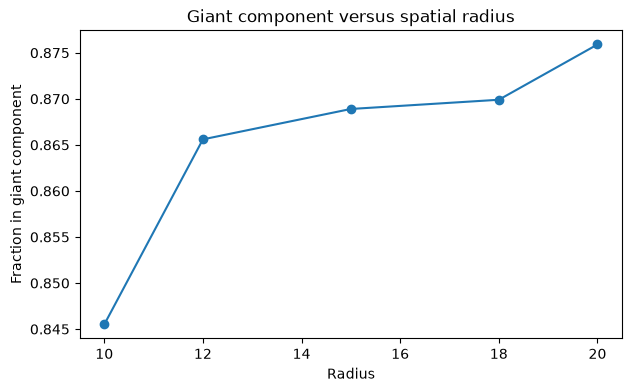

In [4]:
plt.figure(figsize=(7, 4))

plt.plot(
    radius_results["radius"],
    radius_results["giant_component_fraction"],
    marker="o"
)

plt.xlabel("Radius")
plt.ylabel("Fraction in giant component")
plt.title("Giant component versus spatial radius")

plt.show()

## Final spatial network definition

Based on the empirical nearest-neighbor distances and the radius sensitivity analysis, the final network uses a spatial radius of:

\[
r = 15
\]

Two cells are connected if the Euclidean distance between their centroids is at most 15 spatial units.

This choice gives a local network with moderate mean degree while avoiding the rapid increase in edge density observed at larger radii.

Final network summary:

- Nodes: 10,000
- Edges: 50,583
- Mean degree: 10.1166
- Isolated nodes: 26
- Connected components: 41
- Largest connected component: 8,689 cells
- Giant-component fraction: 0.8689

In [5]:
FINAL_RADIUS = 15

final_pairs = tree.query_pairs(r=FINAL_RADIUS)

G = nx.Graph()

# Use cell IDs as node labels
G.add_nodes_from(cells["cell_id"])

index_to_cell = dict(enumerate(cells["cell_id"]))

G.add_edges_from(
    (index_to_cell[i], index_to_cell[j])
    for i, j in final_pairs
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Mean degree:", 2 * G.number_of_edges() / G.number_of_nodes())
print("Isolates:", nx.number_of_isolates(G))
print("Components:", nx.number_connected_components(G))

Nodes: 10000
Edges: 50583
Mean degree: 10.1166
Isolates: 26
Components: 41


In [6]:
GRAPH_PATH = DATA_ROOT / "processed" / "WT4_spatial_network_r15.graphml"

nx.write_graphml(G, GRAPH_PATH)

print("Saved graph:", GRAPH_PATH)

Saved graph: E:\Network_Theory_Class\NT_and_ABM_data\processed\WT4_spatial_network_r15.graphml


In [7]:
largest_component = max(nx.connected_components(G), key=len)

network_summary = pd.DataFrame([{
    "sample": "WT4",
    "n_nodes": G.number_of_nodes(),
    "n_edges": G.number_of_edges(),
    "mean_degree": 2 * G.number_of_edges() / G.number_of_nodes(),
    "radius": FINAL_RADIUS,
    "isolates": nx.number_of_isolates(G),
    "components": nx.number_connected_components(G),
    "giant_component_size": len(largest_component),
    "giant_component_fraction": len(largest_component) / G.number_of_nodes(),
}])

summary_path = DATA_ROOT / "processed" / "WT4_spatial_network_r15_summary.csv"

network_summary.to_csv(summary_path, index=False)

display(network_summary)

,sample,n_nodes,n_edges,mean_degree,radius,isolates,components,giant_component_size,giant_component_fraction
0,WT4,10000,50583,10.1166,15,26,41,8689,0.8689
